# TP — Prédiction des feux de forêt (Forest Fires)

> **Problème** : prédire la surface brûlée `area` (en hectares) à partir d’indices météo et d’indices FWI (Fire Weather Index).

## Contexte scientifique (FWI)
Les indices **FWI** résument l’« état du combustible » et le danger de propagation d’un feu :
- `FFMC` (*Fine Fuel Moisture Code*) : humidité des combustibles fins (réagit vite aux variations météo).
- `DMC` (*Duff Moisture Code*) : humidité de la couche organique intermédiaire (réagit à moyen terme).
- `DC` (*Drought Code*) : sécheresse de la couche profonde (tendance long terme).
- `ISI` (*Initial Spread Index*) : potentiel de propagation initiale (dépend notamment du vent).

## Objectif
- **Régression** : prédire `area` (surface brûlée).
- **Variante** : classification binaire *feu majeur* (`area` > 0) vs *petit feu* (`area` = 0).

## Plan du rapport
1. Données & qualité (types, valeurs manquantes)
2. Distribution de `area` et transformation $\log(1+\text{area})$
3. Corrélations simples (Température / Vent vs surface brûlée)
4. Modélisation régression : Linear Regression (base), SVR, KNN
5. Variante classification binaire : Logistic Regression, SVC, KNN
6. Bonus : top-4 variables + comparaison log vs non-log
7. Interprétation & conclusion

Dataset : `forestfires.csv` (dans le même dossier).

In [2]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import Markdown, display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    recall_score,
    f1_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    KFold,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC, SVR

RANDOM_STATE = 42
sns.set_theme()
pd.set_option('display.max_columns', 200)

In [5]:
from pathlib import Path

data_path = Path('forestfires.csv')
if not data_path.exists():
    raise FileNotFoundError(f"Impossible de trouver {data_path.resolve()}")

df = pd.read_csv(data_path)
df.head()

,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
0,7,5,mar,fri,86.2,26.2,94.3,5.1,8.2,51,6.7,0.0,0.0
1,7,4,oct,tue,90.6,35.4,669.1,6.7,18.0,33,0.9,0.0,0.0
2,7,4,oct,sat,90.6,43.7,686.9,6.7,14.6,33,1.3,0.0,0.0
3,8,6,mar,fri,91.7,33.3,77.5,9.0,8.3,97,4.0,0.2,0.0
4,8,6,mar,sun,89.3,51.3,102.2,9.6,11.4,99,1.8,0.0,0.0


## 0) Données : aperçu et variables

> **Cible** : `area` (hectares brûlés).

> **Variables explicatives (exemples)** :
- Coordonnées/zone : `X`, `Y`
- Calendrier : `month`, `day` (catégorielles)
- Indices FWI : `FFMC`, `DMC`, `DC`, `ISI`
- Météo instantanée : `temp`, `RH` (humidité relative), `wind`, `rain`

**Remarque** : `month` et `day` sont encodées en *one-hot* dans les modèles (sinon elles ne sont pas exploitables telles quelles).

In [44]:
df.info()

df.isna().sum().sort_values(ascending=False).head(20)

<class 'pandas.DataFrame'>
RangeIndex: 517 entries, 0 to 516
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X       517 non-null    int64  
 1   Y       517 non-null    int64  
 2   month   517 non-null    str    
 3   day     517 non-null    str    
 4   FFMC    517 non-null    float64
 5   DMC     517 non-null    float64
 6   DC      517 non-null    float64
 7   ISI     517 non-null    float64
 8   temp    517 non-null    float64
 9   RH      517 non-null    int64  
 10  wind    517 non-null    float64
 11  rain    517 non-null    float64
 12  area    517 non-null    float64
dtypes: float64(8), int64(3), str(2)
memory usage: 52.6 KB


X        0
Y        0
month    0
day      0
FFMC     0
DMC      0
DC       0
ISI      0
temp     0
RH       0
wind     0
rain     0
area     0
dtype: int64

## 1) Distribution de la cible et transformation log1p

### Pourquoi une transformation ?
La cible `area` est **très asymétrique** : beaucoup d’observations à 0 (aucune surface brûlée) et quelques feux très grands.
Un modèle entraîné directement sur `area` a tendance à être dominé par ces valeurs extrêmes et à mal généraliser.

### Transformation utilisée
On définit :  
$y = \log(1 + \text{area})$
- `log1p` est stable numériquement et gère correctement `area = 0`.
- On entraîne les modèles de régression sur `log_area` (plus « gaussien »).

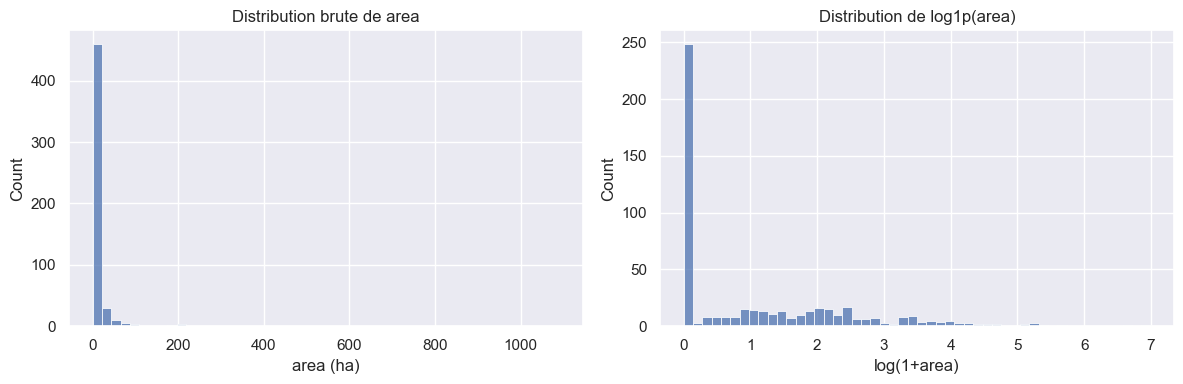

In [45]:
target_col = 'area'
if target_col not in df.columns:
    raise KeyError(f"Colonne cible '{target_col}' absente. Colonnes: {list(df.columns)}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[target_col], bins=50, ax=axes[0])
axes[0].set_title('Distribution brute de area')
axes[0].set_xlabel('area (ha)')

df['log_area'] = np.log1p(df[target_col])
sns.histplot(df['log_area'], bins=50, ax=axes[1])
axes[1].set_title('Distribution de log1p(area)')
axes[1].set_xlabel('log(1+area)')

plt.tight_layout()

## 2) Corrélations : Température / Vent vs surface brûlée

On commence par des corrélations simples :
- **Pearson** : relation linéaire (sensible aux outliers).
- **Spearman** : relation monotone (plus robuste aux distributions non gaussiennes).

⚠️ Ici, une corrélation faible n’est pas surprenante : la surface brûlée dépend de nombreux facteurs (état du combustible, interventions, conditions locales), et `area` contient beaucoup de zéros.

,area,log_area
temp,0.097844,0.053487
wind,0.012317,0.066973


,area,log_area
temp,0.078696,0.078696
wind,0.053196,0.053196


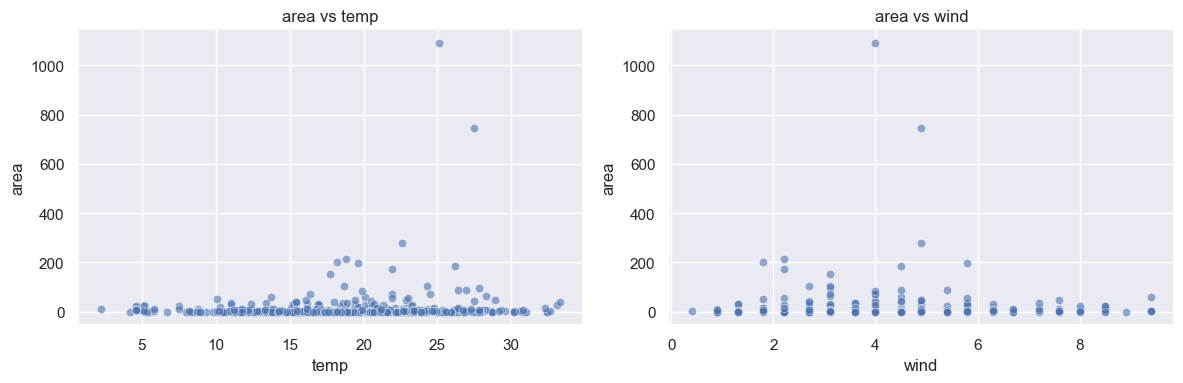

In [46]:
for col in ['temp', 'wind']:
    if col not in df.columns:
        print(f"⚠️ Colonne '{col}' absente dans ce dataset.")

cols_to_check = [c for c in ['temp', 'wind'] if c in df.columns]
if cols_to_check:
    corr_pearson = df[cols_to_check + ['area', 'log_area']].corr(numeric_only=True, method='pearson')
    corr_spearman = df[cols_to_check + ['area', 'log_area']].corr(numeric_only=True, method='spearman')
    display(corr_pearson.loc[cols_to_check, ['area', 'log_area']])
    display(corr_spearman.loc[cols_to_check, ['area', 'log_area']])

    fig, axes = plt.subplots(1, len(cols_to_check), figsize=(6 * len(cols_to_check), 4))
    if len(cols_to_check) == 1:
        axes = [axes]
    for ax, col in zip(axes, cols_to_check):
        sns.scatterplot(data=df, x=col, y='area', alpha=0.6, ax=ax)
        ax.set_title(f"area vs {col}")
    plt.tight_layout()

## 3) Préparation des données (features)

### Choix de la cible
- On modélise **`log_area = log1p(area)`** pour la régression.
- Pour la classification, on utilise la cible binaire **`area > 0`**.

### Prétraitements
- **Variables numériques** : standardisation (moyenne 0, variance 1) → important pour SVR/KNN.
- **Variables catégorielles** (`month`, `day`) : encodage **one-hot**.

### Validation
On conserve une séparation **train/test** (20% test) et, quand on cherche des hyperparamètres (SVR/KNN), on fait la **CV uniquement sur le train** pour éviter la fuite d’information.

In [47]:
# Définition X / y (régression)
y_reg = df['log_area'].copy()
X = df.drop(columns=['area', 'log_area'], errors='ignore')

# Colonnes catégorielles usuelles dans ce dataset
categorical_cols = [c for c in ['month', 'day'] if c in X.columns]
numeric_cols = [c for c in X.columns if c not in categorical_cols]

preprocess = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
    ],
    remainder='drop',
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_reg, test_size=0.2, random_state=RANDOM_STATE
 )

X_train.shape, X_test.shape

((413, 12), (104, 12))

### Mesures d’évaluation
- **RMSE** en régression (sur `log_area`) :  
$\mathrm{RMSE}(y,\hat{y}) = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}$
- **Accuracy** en classification binaire : proportion de prédictions correctes.

On rapporte RMSE sur l’espace log (cohérent avec l’entraînement). Dans le bonus, on montre aussi une comparaison sur l’échelle hectares en reconvertissant $\exp(\hat{y})-1$ (avec prudence).

In [48]:
# Baseline régression (sur log_area) + CV 10-fold
dummy_reg = Pipeline(steps=[
    ('preprocess', preprocess),
    ('model', DummyRegressor(strategy='median'))
])

dummy_reg_res = evaluate_regression('DummyRegressor(median)', dummy_reg, X_train, y_train, X_test, y_test)
dummy_reg_cv = crossval_regression(dummy_reg, X_train, y_train, n_splits=10)

pd.DataFrame([{**dummy_reg_res, **dummy_reg_cv}])

,model,rmse_train_log,rmse_test_log,mae_train_log,mae_test_log,cv_rmse_log,cv_mae_log
0,DummyRegressor(median),1.530018,1.643215,1.089388,1.133352,1.519 ± 0.279,1.103 ± 0.200


## 4) Baselines et validation croisée (10-fold)

Avant d’interpréter les modèles, on ajoute :
- une **baseline** en régression (prédire une constante) ;
- une **baseline** en classification (classe majoritaire) ;
- une **validation croisée 10 folds** pour estimer la performance moyenne et sa variabilité.

Cela évite de conclure à partir d’un seul split train/test.

In [49]:
def rmse(y_true, y_pred):
    # Compatibilité scikit-learn: certaines versions n'acceptent pas `squared=False`
    try:
        return mean_squared_error(y_true, y_pred, squared=False)
    except TypeError:
        return float(np.sqrt(mean_squared_error(y_true, y_pred)))

def mae(y_true, y_pred):
    return float(mean_absolute_error(y_true, y_pred))

def evaluate_regression(name, model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)
    out = {
        'model': name,
        'rmse_train_log': rmse(y_train, pred_train),
        'rmse_test_log': rmse(y_test, pred_test),
        'mae_train_log': mae(y_train, pred_train),
        'mae_test_log': mae(y_test, pred_test),
    }
    return out

def _cv_summary(scores: np.ndarray) -> str:
    return f"{scores.mean():.3f} ± {scores.std():.3f}"

def crossval_regression(model, X, y, *, n_splits=10):
    cv = KFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    res = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring={
            'rmse': 'neg_root_mean_squared_error',
            'mae': 'neg_mean_absolute_error',
        },
        n_jobs=1,
        return_train_score=False,
)
    return {
        'cv_rmse_log': _cv_summary(-res['test_rmse']),
        'cv_mae_log': _cv_summary(-res['test_mae']),
    }

def crossval_classification(model, X, y, *, n_splits=10):
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    res = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring={
            'accuracy': 'accuracy',
            'precision': 'precision',
            'recall': 'recall',
            'f1': 'f1',
        },
        n_jobs=1,
        return_train_score=False,
)
    return {
        'cv_accuracy': _cv_summary(res['test_accuracy']),
        'cv_precision': _cv_summary(res['test_precision']),
        'cv_recall': _cv_summary(res['test_recall']),
        'cv_f1': _cv_summary(res['test_f1']),
    }

## 5) Régression — Linear Regression (base)

On entraîne une régression linéaire sur la cible transformée `log_area` et on évalue par RMSE/MAE en espace log.
Cette approche sert de **référence** avant d’essayer des modèles non-linéaires.

In [50]:
linreg = Pipeline(steps=[
    ('preprocess', preprocess),
    ('model', LinearRegression()),
])

results_reg = []
results_reg.append(evaluate_regression('LinearRegression', linreg, X_train, y_train, X_test, y_test))
pd.DataFrame(results_reg)

,model,rmse_train_log,rmse_test_log,mae_train_log,mae_test_log
0,LinearRegression,1.31605,1.517074,1.071833,1.202107


## 6) Régression non-linéaire — SVR et KNN

On fait une recherche d’hyperparamètres via `GridSearchCV` avec **validation croisée 10 folds** (demandé).
Le score optimisé est le **RMSE (log)** via `neg_root_mean_squared_error`.

In [51]:
# --- SVR ---
svr_pipe = Pipeline(steps=[
    ('preprocess', preprocess),
    ('model', SVR()),
])

svr_param_grid = {
    'model__kernel': ['rbf'],
    'model__C': [1, 10, 100],
    'model__gamma': ['scale', 0.1, 0.01],
    'model__epsilon': [0.05, 0.1, 0.2],
}

# CV en 10 folds (demandé) ; n_jobs=1 pour éviter certains conflits OpenMP
svr_search = GridSearchCV(
    svr_pipe,
    param_grid=svr_param_grid,
    scoring='neg_root_mean_squared_error',
    cv=10,
    n_jobs=1,
    verbose=0,
)
svr_search.fit(X_train, y_train)
svr_search.best_params_, -svr_search.best_score_

({'model__C': 1,
  'model__epsilon': 0.2,
  'model__gamma': 0.1,
  'model__kernel': 'rbf'},
 np.float64(1.431258250325386))

In [52]:
results_reg.append(evaluate_regression('SVR(best)', svr_search.best_estimator_, X_train, y_train, X_test, y_test))
pd.DataFrame(results_reg).sort_values('rmse_test_log')

,model,rmse_train_log,rmse_test_log,mae_train_log,mae_test_log
0,LinearRegression,1.316050,1.517074,1.071833,1.202107
1,SVR(best),1.234281,1.572076,0.816566,1.122676


In [53]:
# --- KNN Regressor ---
knn_pipe = Pipeline(steps=[
    ('preprocess', preprocess),
    ('model', KNeighborsRegressor()),
])

knn_param_grid = {
    'model__n_neighbors': [3, 5, 10, 20, 50],
    'model__weights': ['uniform', 'distance'],
    'model__p': [1, 2],  # 1=Manhattan, 2=Euclidean
}

# CV en 10 folds (demandé) ; n_jobs=1 pour éviter certains conflits OpenMP
knn_search = GridSearchCV(
    knn_pipe,
    param_grid=knn_param_grid,
    scoring='neg_root_mean_squared_error',
    cv=10,
    n_jobs=1,
    verbose=0,
)
knn_search.fit(X_train, y_train)
knn_search.best_params_, -knn_search.best_score_

({'model__n_neighbors': 50, 'model__p': 2, 'model__weights': 'distance'},
 np.float64(1.3492983649170571))

In [54]:
results_reg.append(evaluate_regression('KNNRegressor(best)', knn_search.best_estimator_, X_train, y_train, X_test, y_test))
pd.DataFrame(results_reg).sort_values('rmse_test_log')

,model,rmse_train_log,rmse_test_log,mae_train_log,mae_test_log
2,KNNRegressor(best),0.107154,1.490495,0.016248,1.205866
0,LinearRegression,1.316050,1.517074,1.071833,1.202107
1,SVR(best),1.234281,1.572076,0.816566,1.122676


In [55]:
# Tableau récapitulatif : métriques test + CV 10 folds (sur train)
reg_models = {
    'DummyRegressor(median)': dummy_reg,
    'LinearRegression': linreg,
    'SVR(best)': svr_search.best_estimator_,
    'KNNRegressor(best)': knn_search.best_estimator_,
}

rows = []
for name, model in reg_models.items():
    row = evaluate_regression(name, model, X_train, y_train, X_test, y_test)
    row.update(crossval_regression(model, X_train, y_train, n_splits=10))
    rows.append(row)

reg_summary = pd.DataFrame(rows).sort_values('rmse_test_log')
reg_summary

,model,rmse_train_log,rmse_test_log,mae_train_log,mae_test_log,cv_rmse_log,cv_mae_log
3,KNNRegressor(best),0.107154,1.490495,0.016248,1.205866,1.352 ± 0.185,1.121 ± 0.123
1,LinearRegression,1.316050,1.517074,1.071833,1.202107,1.509 ± 0.340,1.180 ± 0.145
2,SVR(best),1.234281,1.572076,0.816566,1.122676,1.442 ± 0.244,1.090 ± 0.154
0,DummyRegressor(median),1.530018,1.643215,1.089388,1.133352,1.519 ± 0.279,1.103 ± 0.200


In [56]:
# Discussion automatique — Régression (affichage Markdown)
best_test = reg_summary.iloc[0]
dummy_row = reg_summary[reg_summary['model'].str.contains('DummyRegressor')].iloc[0]

lines = []
lines.append('### Régression')
lines.append(f"- Meilleur modèle (RMSE test sur `log_area`) : **{best_test['model']}** avec RMSE={best_test['rmse_test_log']:.3f} et MAE={best_test['mae_test_log']:.3f}.")
lines.append(f"- Baseline : **{dummy_row['model']}** avec RMSE={dummy_row['rmse_test_log']:.3f} et MAE={dummy_row['mae_test_log']:.3f} (test).")
lines.append(f"- En CV 10-fold (train) : {best_test['model']} → RMSE {best_test['cv_rmse_log']} / MAE {best_test['cv_mae_log']} ; baseline → RMSE {dummy_row['cv_rmse_log']} / MAE {dummy_row['cv_mae_log']}.")
lines.append("- Lecture : si le modèle fait mieux que la baseline, il capte un signal réel ; si l’écart train→test est grand (ex: KNN), il peut y avoir sur-apprentissage.")

display(Markdown('\n'.join(lines)))

### Régression
- Meilleur modèle (RMSE test sur `log_area`) : **KNNRegressor(best)** avec RMSE=1.490 et MAE=1.206.
- Baseline : **DummyRegressor(median)** avec RMSE=1.643 et MAE=1.133 (test).
- En CV 10-fold (train) : KNNRegressor(best) → RMSE 1.352 ± 0.185 / MAE 1.121 ± 0.123 ; baseline → RMSE 1.519 ± 0.279 / MAE 1.103 ± 0.200.
- Lecture : si le modèle fait mieux que la baseline, il capte un signal réel ; si l’écart train→test est grand (ex: KNN), il peut y avoir sur-apprentissage.

## Discussion des résultats (automatique)

Les paragraphes ci-dessous sont générés à partir des tableaux de synthèse (régression et classification).
Ils permettent d’écrire une discussion “rapport” sans recopier manuellement les chiffres.

## 7) Synthèse régression : test + CV 10-fold

On synthétise :
- performances sur le **test** (RMSE/MAE sur `log_area`) ;
- et une estimation plus robuste via **CV 10 folds** (moyenne ± écart-type) sur le train.

⚠️ Des scores bien meilleurs sur le train que sur le test suggèrent du sur-apprentissage (fréquent pour KNN).

## 8) Variante classification binaire

On transforme le problème en :
- **Feu majeur** : `area` > 0
- **Petit feu / pas de feu** : `area` = 0

On évalue avec :
- **Accuracy** (facile à lire)
- **Precision/Recall/F1** (plus informatif si la classe positive est rare).

On utilise une séparation train/test **stratifiée**.

In [57]:
y_clf = (df['area'] > 0).astype(int)
X_clf = df.drop(columns=['area', 'log_area'], errors='ignore')

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=RANDOM_STATE, stratify=y_clf
 )

yc_train.value_counts(normalize=True).rename('train_ratio')

area
1    0.523002
0    0.476998
Name: train_ratio, dtype: float64

In [58]:
def evaluate_classifier(name, model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    pred_test = model.predict(X_test)
    return {'model': name, 'accuracy_test': accuracy_score(y_test, pred_test)}

clf_results = []

# Baseline : Logistic Regression
logreg = Pipeline(steps=[
    ('preprocess', preprocess),
    ('model', LogisticRegression(max_iter=2000, class_weight='balanced'))
])
clf_results.append(evaluate_classifier('LogisticRegression', logreg, Xc_train, yc_train, Xc_test, yc_test))

# SVM Classifier
svc = Pipeline(steps=[
    ('preprocess', preprocess),
    ('model', SVC(kernel='rbf', C=10, gamma='scale', class_weight='balanced'))
])
clf_results.append(evaluate_classifier('SVC(rbf)', svc, Xc_train, yc_train, Xc_test, yc_test))

# KNN Classifier
knn_clf = Pipeline(steps=[
    ('preprocess', preprocess),
    ('model', KNeighborsClassifier(n_neighbors=25, weights='distance'))
])
clf_results.append(evaluate_classifier('KNNClassifier', knn_clf, Xc_train, yc_train, Xc_test, yc_test))

pd.DataFrame(clf_results).sort_values('accuracy_test', ascending=False)

,model,accuracy_test
1,SVC(rbf),0.682692
2,KNNClassifier,0.634615
0,LogisticRegression,0.576923


,Prédit 0,Prédit 1
Vrai 0,31,19
Vrai 1,14,40


              precision    recall  f1-score   support

      area=0       0.69      0.62      0.65        50
      area>0       0.68      0.74      0.71        54

    accuracy                           0.68       104
   macro avg       0.68      0.68      0.68       104
weighted avg       0.68      0.68      0.68       104



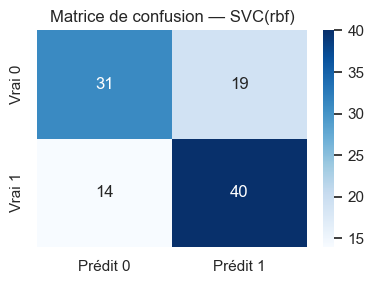

In [59]:
# Matrice de confusion + rapport détaillé pour le meilleur modèle (selon F1 sur le test)
best_name = clf_summary.iloc[0]['model']
best_model = clf_models[best_name]
best_model.fit(Xc_train, yc_train)
pred_best = best_model.predict(Xc_test)

cm = confusion_matrix(yc_test, pred_best)
cm_df = pd.DataFrame(cm, index=['Vrai 0', 'Vrai 1'], columns=['Prédit 0', 'Prédit 1'])
display(cm_df)

plt.figure(figsize=(4, 3))
sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues')
plt.title(f"Matrice de confusion — {best_name}")
plt.tight_layout()

print(classification_report(yc_test, pred_best, target_names=['area=0', 'area>0'], zero_division=0))

In [60]:
# Discussion automatique — Classification (affichage Markdown)
best_clf = clf_summary.iloc[0]

lines = []
lines.append('### Classification (area > 0)')
lines.append(f"- Meilleur modèle (F1 test) : **{best_clf['model']}** avec Accuracy={best_clf['accuracy_test']:.3f}, Precision={best_clf['precision_test']:.3f}, Recall={best_clf['recall_test']:.3f}, F1={best_clf['f1_test']:.3f}.")
lines.append(f"- En CV 10-fold (train) pour ce modèle : Accuracy {best_clf['cv_accuracy']}, F1 {best_clf['cv_f1']}.")
lines.append("- Lecture : la matrice de confusion montre le compromis faux positifs / faux négatifs ; selon l’objectif (détecter tous les feux >0 vs limiter les fausses alertes), on privilégie le Recall ou la Precision.")

display(Markdown('\n'.join(lines)))

### Classification (area > 0)
- Meilleur modèle (F1 test) : **SVC(rbf)** avec Accuracy=0.683, Precision=0.678, Recall=0.741, F1=0.708.
- En CV 10-fold (train) pour ce modèle : Accuracy 0.545 ± 0.070, F1 0.583 ± 0.052.
- Lecture : la matrice de confusion montre le compromis faux positifs / faux négatifs ; selon l’objectif (détecter tous les feux >0 vs limiter les fausses alertes), on privilégie le Recall ou la Precision.

In [61]:
def evaluate_classifier_metrics(name, model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    return {
        'model': name,
        'accuracy_test': float(accuracy_score(y_test, pred)),
        'precision_test': float(precision_score(y_test, pred, zero_division=0)),
        'recall_test': float(recall_score(y_test, pred, zero_division=0)),
        'f1_test': float(f1_score(y_test, pred, zero_division=0)),
    }

# Définition des modèles
clf_models = {
    'DummyClassifier(most_frequent)': Pipeline(steps=[
        ('preprocess', preprocess),
        ('model', DummyClassifier(strategy='most_frequent'))
]),
    'LogisticRegression': Pipeline(steps=[
        ('preprocess', preprocess),
        ('model', LogisticRegression(max_iter=2000, class_weight='balanced'))
]),
    'SVC(rbf)': Pipeline(steps=[
        ('preprocess', preprocess),
        ('model', SVC(kernel='rbf', C=10, gamma='scale', class_weight='balanced'))
]),
    'KNNClassifier': Pipeline(steps=[
        ('preprocess', preprocess),
        ('model', KNeighborsClassifier(n_neighbors=25, weights='distance'))
]),
}

rows = []
for name, model in clf_models.items():
    row = evaluate_classifier_metrics(name, model, Xc_train, yc_train, Xc_test, yc_test)
    row.update(crossval_classification(model, Xc_train, yc_train, n_splits=10))
    rows.append(row)

clf_summary = pd.DataFrame(rows).sort_values('f1_test', ascending=False)
clf_summary

,model,accuracy_test,precision_test,recall_test,f1_test,cv_accuracy,cv_precision,cv_recall,cv_f1
2,SVC(rbf),0.682692,0.677966,0.740741,0.707965,0.545 ± 0.070,0.566 ± 0.071,0.606 ± 0.058,0.583 ± 0.052
3,KNNClassifier,0.634615,0.617647,0.777778,0.688525,0.554 ± 0.062,0.563 ± 0.054,0.690 ± 0.063,0.618 ± 0.049
0,DummyClassifier(most_frequent),0.519231,0.519231,1.000000,0.683544,0.523 ± 0.010,0.523 ± 0.010,1.000 ± 0.000,0.687 ± 0.009
1,LogisticRegression,0.576923,0.592593,0.592593,0.592593,0.467 ± 0.048,0.492 ± 0.046,0.500 ± 0.070,0.494 ± 0.050


## 9) Synthèse classification : test + CV 10-fold

On compare :
- une baseline (classe majoritaire),
- et les modèles (LogReg, SVC, KNN).

On rapporte :
- métriques **sur le test** (Accuracy/Precision/Recall/F1),
- métriques **en CV 10 folds** sur le train (moyenne ± écart-type),
- et une **matrice de confusion** pour le meilleur modèle (selon F1 sur le test).

## 10) Interprétation & conclusion

### Points clés
- La variable `area` contient beaucoup de zéros et quelques valeurs extrêmes : la **prédiction des grands feux** reste difficile.
- Les corrélations simples (température/vent) sont faibles : le phénomène est multi-factoriel et bruité.
- Les modèles non-linéaires peuvent gagner un peu en RMSE log, mais il faut vérifier la **stabilité** via la CV (10 folds).

### Ce qu’on retient (rapport TP)
- Comparer aux **baselines** est essentiel : si un modèle ne fait pas mieux qu’un Dummy, il n’apporte pas d’information utile.
- La transformation $\log(1+\text{area})$ rend l’apprentissage plus stable, mais ne “résout” pas le problème des extrêmes.
- Pour la classification `area>0`, l’Accuracy seule est insuffisante : on regarde aussi **Precision/Recall/F1** + matrice de confusion.

## Conclusion (à reprendre dans le compte-rendu)

- La prédiction de `area` est difficile à cause de la distribution très déséquilibrée (beaucoup de zéros + quelques extrêmes).
- La transformation $\log(1+\text{area})$ stabilise l’apprentissage et permet une comparaison plus pertinente des modèles.
- Les modèles non-linéaires peuvent améliorer la performance, mais il faut s’appuyer sur la **CV 10-fold** pour juger la robustesse.
- Pour la variante classification (`area>0`), le couple **F1 + matrice de confusion** est plus informatif que l’accuracy seule.

**Limites / pistes** (optionnel) : feature engineering (saisonnalité), modèles d’ensemble, calibration / seuils pour prioriser Recall vs Precision.

## 11) Bonus (optionnel)

### Bonus 1 — Sélection de variables (top-4)
On sélectionne 4 variables via **permutation importance** (sur un split interne du train pour éviter d’utiliser le test).

### Bonus 2 — Sans vs avec log
On compare un modèle entraîné directement sur `area` et un modèle entraîné sur `log1p(area)` puis reconverti en hectares.
Cette comparaison doit être interprétée avec prudence (les grands feux dominent l’erreur en hectares).

In [62]:
# Bonus 1: top-4 variables via permutation importance (sur un split interne du train)
X_pi_tr, X_pi_val, y_pi_tr, y_pi_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=RANDOM_STATE
 )

# On prend un modèle stable (LinearRegression) pour estimer l'importance des variables
pi_model = Pipeline(steps=[
    ('preprocess', preprocess),
    ('model', LinearRegression()),
])
pi_model.fit(X_pi_tr, y_pi_tr)

pi = permutation_importance(
    pi_model,
    X_pi_val,
    y_pi_val,
    scoring='neg_root_mean_squared_error',
    n_repeats=15,
    random_state=RANDOM_STATE,
)

pi_df = pd.DataFrame({
    'feature': list(X_pi_val.columns),
    'importance_mean': pi.importances_mean,
    'importance_std': pi.importances_std,
}).sort_values('importance_mean', ascending=False)

top4 = pi_df.head(4)['feature'].tolist()
top4, pi_df.head(10)

(['DC', 'month', 'DMC', 'temp'],
    feature  importance_mean  importance_std
 6       DC         0.121682        0.066053
 2    month         0.102983        0.049824
 5      DMC         0.044022        0.043152
 8     temp         0.033417        0.016506
 3      day         0.020958        0.016131
 0        X         0.005878        0.018176
 9       RH         0.005698        0.010076
 4     FFMC         0.005158        0.002888
 10    wind         0.003663        0.005709
 7      ISI         0.000552        0.000893)

In [63]:
# Bonus 1 (suite): comparer régression linéaire avec seulement top4 (Permutation Importance)
X_top4 = df[top4].copy()
y_log = df['log_area'].copy()

# Détection robuste des types (le dataset peut avoir dtype 'str' et pas 'object')
categorical_top = [c for c in X_top4.columns if not pd.api.types.is_numeric_dtype(X_top4[c])]
numeric_top = [c for c in X_top4.columns if c not in categorical_top]

preprocess_top4 = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_top),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_top),
    ],
    remainder='drop',
)

Xtr, Xte, ytr, yte = train_test_split(
    X_top4, y_log, test_size=0.2, random_state=RANDOM_STATE
 )

linreg_top4 = Pipeline(steps=[('preprocess', preprocess_top4), ('model', LinearRegression())])
evaluate_regression('LinearRegression(top4 PI)', linreg_top4, Xtr, ytr, Xte, yte)

{'model': 'LinearRegression(top4 PI)',
 'rmse_train_log': 1.3295925008469074,
 'rmse_test_log': 1.4969234530385354,
 'mae_train_log': 1.0862171271421333,
 'mae_test_log': 1.1829725559313562}

In [64]:
# Bonus 2: comparer avec et sans transformation log1p(area) sur la MÊME échelle (hectares)
y_area = df['area'].copy()
X_all = df.drop(columns=['area', 'log_area'], errors='ignore')

Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(
    X_all, y_area, test_size=0.2, random_state=RANDOM_STATE
 )

# Modèle entraîné directement sur area
linreg_raw = Pipeline(steps=[('preprocess', preprocess), ('model', LinearRegression())])
linreg_raw.fit(Xa_tr, ya_tr)
pred_area_raw = linreg_raw.predict(Xa_te)
rmse_area_raw = rmse(ya_te, pred_area_raw)

# Modèle entraîné sur log1p(area), puis reconverti en area
y_log_all = np.log1p(y_area)
Xl_tr, Xl_te, yl_tr, yl_te = train_test_split(
    X_all, y_log_all, test_size=0.2, random_state=RANDOM_STATE
 )
linreg_log = Pipeline(steps=[('preprocess', preprocess), ('model', LinearRegression())])
linreg_log.fit(Xl_tr, yl_tr)
pred_log = linreg_log.predict(Xl_te)
pred_area_from_log = np.maximum(0, np.expm1(pred_log))
rmse_area_from_log = rmse(ya_te, pred_area_from_log)

pd.DataFrame([
    {'model': 'LinearRegression(raw area)', 'rmse_test_area_ha': rmse_area_raw},
    {'model': 'LinearRegression(log1p -> area)', 'rmse_test_area_ha': rmse_area_from_log},
]).sort_values('rmse_test_area_ha')

,model,rmse_test_area_ha
0,LinearRegression(raw area),107.766760
1,LinearRegression(log1p -> area),109.799301


In [65]:
# Export automatique pour la présentation Beamer (tables + figures)
from pathlib import Path
import re

beamer_dir = Path('beamer')
fig_dir = beamer_dir / 'figures'
tables_dir = beamer_dir / 'tables'
fig_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)


def _latex_escape(text: str) -> str:
    # échappe les caractères spéciaux LaTeX les plus courants
    repl = {
        '\\': r'\textbackslash{}',
        '&': r'\&',
        '%': r'\%',
        '$': r'\$',
        '#': r'\#',
        '_': r'\_',
        '{': r'\{',
        '}': r'\}',
        '~': r'\textasciitilde{}',
        '^': r'\textasciicircum{}',
    }
    out = str(text)
    for k, v in repl.items():
        out = out.replace(k, v)
    return out


def _pm_to_latex(s: str) -> str:
    # Convertit "a ± b" en "a $\pm$ b" pour LaTeX
    if not isinstance(s, str):
        return _latex_escape(str(s))
    if '±' in s:
        left, right = [t.strip() for t in s.split('±', 1)]
        return f"{_latex_escape(left)} $\\pm$ {_latex_escape(right)}"
    return _latex_escape(s)


# --- Tables LaTeX depuis reg_summary / clf_summary ---
missing = []
for varname in ['reg_summary', 'clf_summary']:
    if varname not in globals():
        missing.append(varname)

if missing:
    raise RuntimeError(
        "Variables manquantes dans le kernel : " + ', '.join(missing) +
        ". Exécute d'abord les cellules qui construisent reg_summary et clf_summary."
    )

# Régression
reg_cols_needed = ['model', 'rmse_test_log', 'cv_rmse_log']
for c in reg_cols_needed:
    if c not in reg_summary.columns:
        raise KeyError(f"Colonne '{c}' absente de reg_summary. Colonnes: {list(reg_summary.columns)}")

reg_lines = []
reg_lines.append(r"\begin{tabular}{lcc}")
reg_lines.append(r"\toprule")
reg_lines.append(r"Modèle & RMSE (test, log) & CV 10-fold RMSE (log) \\")
reg_lines.append(r"\midrule")

# On garde l'ordre du tableau (déjà trié dans le notebook)
for _, row in reg_summary.iterrows():
    model = _latex_escape(row['model'])
    rmse_test = f"{float(row['rmse_test_log']):.3f}"
    cv_rmse = _pm_to_latex(row['cv_rmse_log'])
    reg_lines.append(fr"{model} & {rmse_test} & {cv_rmse} \\")

reg_lines.append(r"\bottomrule")
reg_lines.append(r"\end{tabular}")

(regression_table_path := tables_dir / 'regression_table.tex').write_text(
    "\n".join(reg_lines), encoding='utf-8'
)

# Classification
clf_cols_needed = ['model', 'f1_test', 'cv_f1']
for c in clf_cols_needed:
    if c not in clf_summary.columns:
        raise KeyError(f"Colonne '{c}' absente de clf_summary. Colonnes: {list(clf_summary.columns)}")

clf_lines = []
clf_lines.append(r"\begin{tabular}{lcc}")
clf_lines.append(r"\toprule")
clf_lines.append(r"Modèle & F1 (test) & CV 10-fold F1 \\")
clf_lines.append(r"\midrule")
for _, row in clf_summary.iterrows():
    model = _latex_escape(row['model'])
    f1_test = f"{float(row['f1_test']):.3f}"
    cv_f1 = _pm_to_latex(row['cv_f1'])
    clf_lines.append(fr"{model} & {f1_test} & {cv_f1} \\")
clf_lines.append(r"\bottomrule")
clf_lines.append(r"\end{tabular}")

(classification_table_path := tables_dir / 'classification_table.tex').write_text(
    "\n".join(clf_lines), encoding='utf-8'
)

# Bonus (texte LaTeX léger)
bonus_path = beamer_dir / 'bonus_auto.tex'
_top4 = globals().get('top4', None)
rmse_raw = globals().get('rmse_area_raw', None)
rmse_from_log = globals().get('rmse_area_from_log', None)

bonus_lines = []
if isinstance(_top4, list) and len(_top4) > 0:
    top4_tex = ', '.join([r"\texttt{" + _latex_escape(x) + "}" for x in _top4])
    bonus_lines.append(r"\textbf{Top-4 variables (Permutation Importance) :} " + top4_tex + r"\\")

if isinstance(rmse_raw, (int, float)) and isinstance(rmse_from_log, (int, float)):
    bonus_lines.append(
        rf"\textbf{{RMSE (hectares) :}} LinearRegression(raw)={rmse_raw:.3f} ; LinearRegression(log→area)={rmse_from_log:.3f}."
    )

bonus_path.write_text("\n".join(bonus_lines) if bonus_lines else "% (bonus_auto.tex vide)\n", encoding='utf-8')


# --- Figures (re-générées rapidement pour être sûres d'exister) ---
# 1) Histogrammes area / log_area
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['area'], bins=50, ax=axes[0])
axes[0].set_title('Distribution brute de area')
axes[0].set_xlabel('area (ha)')

if 'log_area' not in df.columns:
    df['log_area'] = np.log1p(df['area'])

sns.histplot(df['log_area'], bins=50, ax=axes[1])
axes[1].set_title('Distribution de log1p(area)')
axes[1].set_xlabel('log(1+area)')

plt.tight_layout()
fig.savefig(fig_dir / 'dist_area_log.png', dpi=160, bbox_inches='tight')
plt.close(fig)

# 2) Scatter temp/wind vs area (si colonnes présentes)
for col in ['temp', 'wind']:
    if col in df.columns:
        fig, ax = plt.subplots(1, 1, figsize=(6, 4))
        sns.scatterplot(data=df, x=col, y='area', alpha=0.6, ax=ax)
        ax.set_title(f"area vs {col}")
        plt.tight_layout()
        fig.savefig(fig_dir / f"scatter_{col}_area.png", dpi=160, bbox_inches='tight')
        plt.close(fig)

# 3) Matrice de confusion (si variables dispo, sinon recalcul rapide sur le meilleur modèle)
try:
    cm_df  # noqa: F821
except NameError:
    # Recalcul minimal : reprendre le meilleur modèle du tableau clf_summary
    best_name = clf_summary.iloc[0]['model']
    best_model = clf_models[best_name]
    best_model.fit(Xc_train, yc_train)
    pred_best = best_model.predict(Xc_test)
    cm = confusion_matrix(yc_test, pred_best)
    cm_df = pd.DataFrame(cm, index=['Vrai 0', 'Vrai 1'], columns=['Prédit 0', 'Prédit 1'])

fig, ax = plt.subplots(1, 1, figsize=(4, 3))
sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues', ax=ax)
ax.set_title('Matrice de confusion (meilleur modèle)')
plt.tight_layout()
fig.savefig(fig_dir / 'confusion_matrix_best.png', dpi=200, bbox_inches='tight')
plt.close(fig)


display(Markdown("""
### Export Beamer — OK
- Tables : `beamer/tables/regression_table.tex`, `beamer/tables/classification_table.tex`
- Bonus : `beamer/bonus_auto.tex`
- Figures : `beamer/figures/dist_area_log.png`, `beamer/figures/scatter_temp_area.png`, `beamer/figures/scatter_wind_area.png`, `beamer/figures/confusion_matrix_best.png`
"""))



### Export Beamer — OK
- Tables : `beamer/tables/regression_table.tex`, `beamer/tables/classification_table.tex`
- Bonus : `beamer/bonus_auto.tex`
- Figures : `beamer/figures/dist_area_log.png`, `beamer/figures/scatter_temp_area.png`, `beamer/figures/scatter_wind_area.png`, `beamer/figures/confusion_matrix_best.png`
